In [1]:
!pip install -q kagglehub scikit-learn

import os, random
import numpy as np
import torch, torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import models, transforms
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import confusion_matrix, classification_report

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [17]:
import kagglehub
path = kagglehub.dataset_download("yashdogra/cats-and-dogs")
print("Dataset path:", path)

# Walk the folders; label comes from the parent folder name (cats/dogs)
samples = []
for root, _, files in os.walk(path):
    for f in files:
        if not f.lower().endswith(".jpg"):
            continue
        label = 0 if f[0].isupper() else 1   # capital letter = cat, lowercase = dog
        samples.append((os.path.join(root, f), label))

cats = [s for s in samples if s[1] == 0]
dogs = [s for s in samples if s[1] == 1]
print("Total images found:", len(samples))
print("Cats:", len(cats), "| Dogs:", len(dogs))

Using Colab cache for faster access to the 'cats-and-dogs' dataset.
Dataset path: /kaggle/input/cats-and-dogs
Total images found: 7390
Cats: 2400 | Dogs: 4990


In [14]:
cats = [s for s in samples if s[1] == 0]
dogs = [s for s in samples if s[1] == 1]
print("Cats:", len(cats), "| Dogs:", len(dogs))

Cats: 0 | Dogs: 200


In [18]:
CLASS_NAMES = ["cat", "dog"]

cats = [s for s in samples if s[1] == 0]
dogs = [s for s in samples if s[1] == 1]

N_PER_CLASS = min(100, len(cats), len(dogs))
subset = random.sample(cats, N_PER_CLASS) + random.sample(dogs, N_PER_CLASS)
random.shuffle(subset)
print(f"Subset: {len(subset)} images ({N_PER_CLASS} per class)")

Subset: 200 images (100 per class)


In [16]:
import os, collections

ext_count = collections.Counter()
folder_count = collections.Counter()
examples = {}

for root, dirs, files in os.walk(path):
    for f in files:
        ext = os.path.splitext(f)[1].lower()
        ext_count[ext] += 1
        folder_count[root] += 1
        examples.setdefault(root, []).append(f)

print("File types:", dict(ext_count))
print()
for folder, n in folder_count.items():
    print(f"{folder}  ->  {n} files, e.g. {examples[folder][:3]}")

File types: {'.jpg': 7390, '.mat': 3}

/kaggle/input/cats-and-dogs/images  ->  7393 files, e.g. ['american_pit_bull_terrier_16.jpg', 'leonberger_200.jpg', 'english_cocker_spaniel_35.jpg']


In [12]:
import os
print("Path:", path)
count = 0
for root, dirs, files in os.walk(path):
    print(root, "| subfolders:", dirs[:5], "| files:", files[:3])
    count += 1
    if count > 15:
        break

Path: /kaggle/input/cats-and-dogs
/kaggle/input/cats-and-dogs | subfolders: ['images'] | files: []
/kaggle/input/cats-and-dogs/images | subfolders: [] | files: ['american_pit_bull_terrier_16.jpg', 'leonberger_200.jpg', 'english_cocker_spaniel_35.jpg']


In [10]:
!mkdir -p ~/.kaggle && cp /kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json

In [19]:
weights = models.ResNet50_Weights.IMAGENET1K_V2
model = models.resnet50(weights=weights).to(device).eval()

preprocess = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])
# Same crop without normalization, for display
display_tf = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224)])

CAT_IDX = list(range(281, 286))    # tabby, tiger cat, Persian, Siamese, Egyptian cat
DOG_IDX = list(range(151, 269))    # all ImageNet dog breeds

class PetDataset(Dataset):
    def __init__(self, items): self.items = items
    def __len__(self): return len(self.items)
    def __getitem__(self, i):
        p, y = self.items[i]
        img = Image.open(p).convert("RGB")
        return preprocess(img), y, i

loader = DataLoader(PetDataset(subset), batch_size=32, shuffle=False, num_workers=2)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 196MB/s]


In [20]:
y_true, y_pred, confs = [], [], []

with torch.no_grad():
    for x, y, _ in loader:
        probs = F.softmax(model(x.to(device)), dim=1)
        cat_p = probs[:, CAT_IDX].sum(1)
        dog_p = probs[:, DOG_IDX].sum(1)
        pred = (dog_p > cat_p).long()
        conf = torch.maximum(cat_p, dog_p) / (cat_p + dog_p)  # confidence within cat-vs-dog
        y_true += y.tolist(); y_pred += pred.cpu().tolist(); confs += conf.cpu().tolist()

y_true, y_pred, confs = map(np.array, (y_true, y_pred, confs))
acc = (y_true == y_pred).mean()
print(f"Accuracy: {acc:.4f}\n")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))
print("Confusion matrix:\n", confusion_matrix(y_true, y_pred))

Accuracy: 0.9500

              precision    recall  f1-score   support

         cat       1.00      0.90      0.95       100
         dog       0.91      1.00      0.95       100

    accuracy                           0.95       200
   macro avg       0.95      0.95      0.95       200
weighted avg       0.95      0.95      0.95       200

Confusion matrix:
 [[ 90  10]
 [  0 100]]


Correct: 190, Incorrect: 10


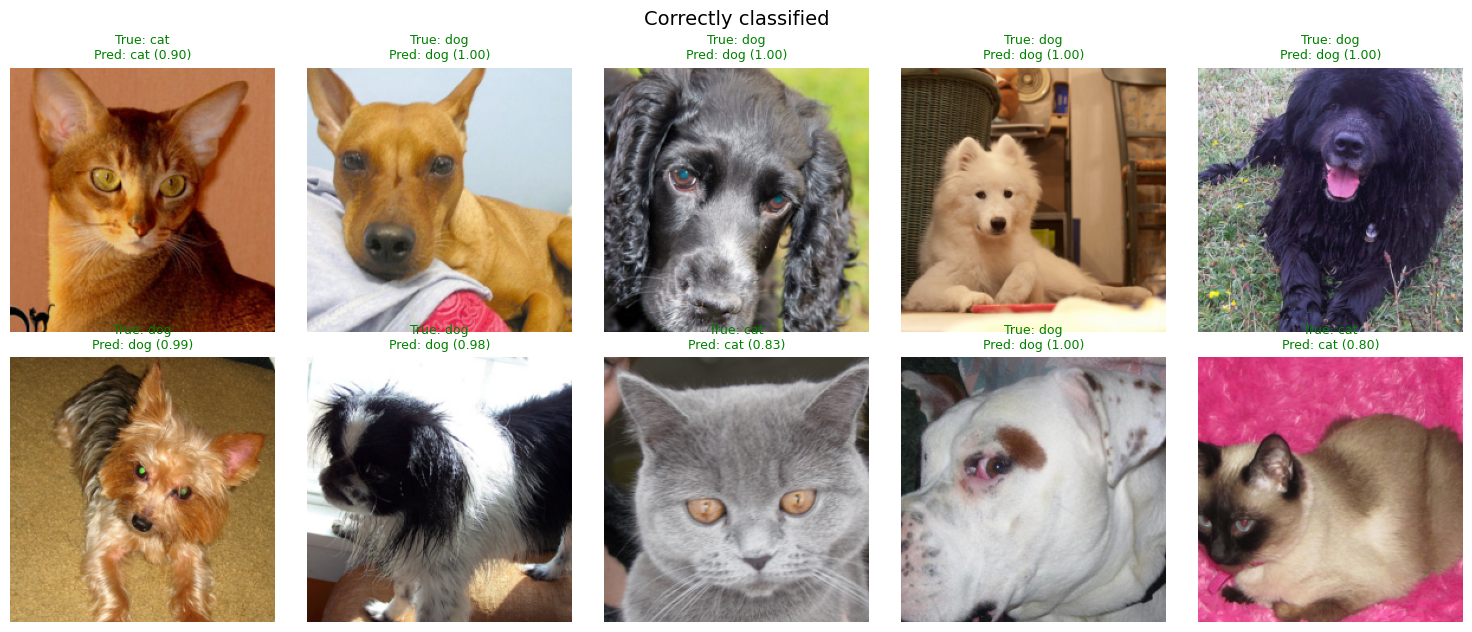

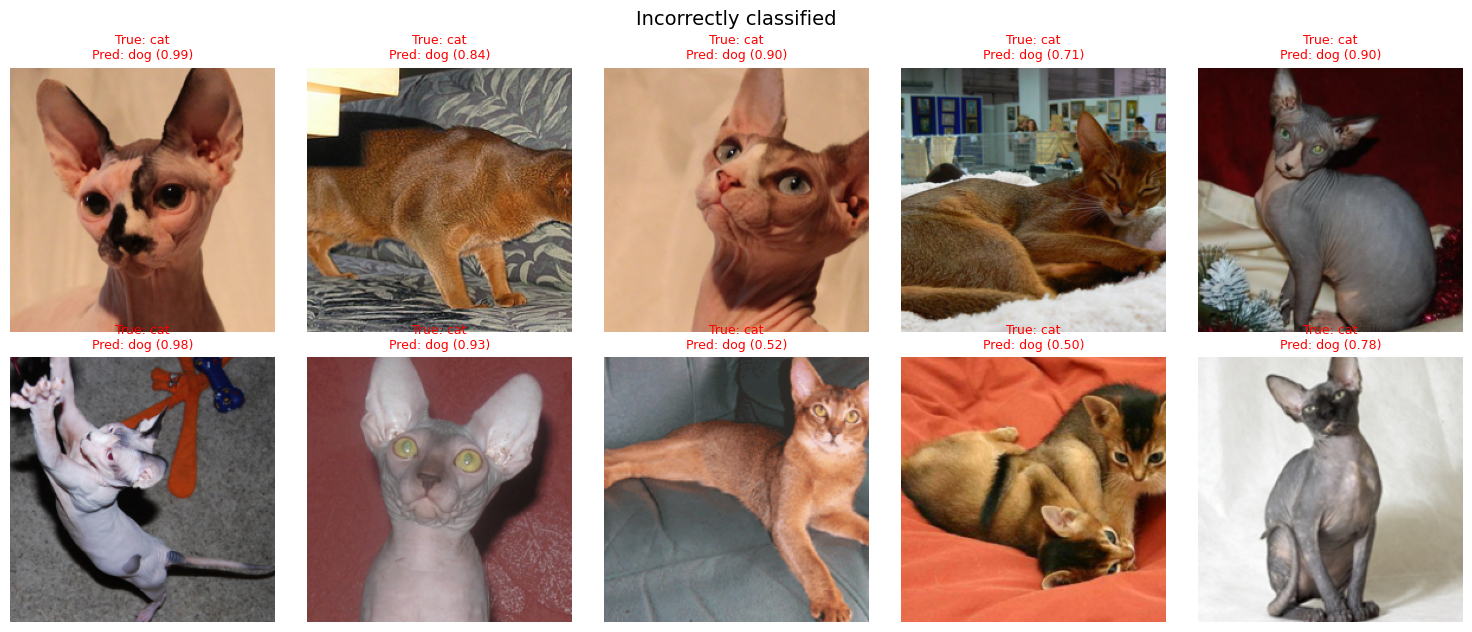

In [21]:
def show_images(indices, title, cols=5):
    indices = list(indices)[:cols * 2]
    rows = max(1, (len(indices) + cols - 1) // cols)
    plt.figure(figsize=(3 * cols, 3.2 * rows))
    for k, i in enumerate(indices):
        img = display_tf(Image.open(subset[i][0]).convert("RGB"))
        plt.subplot(rows, cols, k + 1)
        plt.imshow(img); plt.axis("off")
        plt.title(f"True: {CLASS_NAMES[y_true[i]]}\nPred: {CLASS_NAMES[y_pred[i]]} ({confs[i]:.2f})",
                  color="green" if y_true[i] == y_pred[i] else "red", fontsize=9)
    plt.suptitle(title, fontsize=14); plt.tight_layout(); plt.show()

correct = np.where(y_true == y_pred)[0]
wrong   = np.where(y_true != y_pred)[0]
print(f"Correct: {len(correct)}, Incorrect: {len(wrong)}")

show_images(correct, "Correctly classified")
if len(wrong): show_images(wrong, "Incorrectly classified")

In [22]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model, self.acts, self.grads = model, None, None
        target_layer.register_forward_hook(self._fwd)

    def _fwd(self, module, inp, out):
        self.acts = out
        out.register_hook(lambda g: setattr(self, "grads", g))

    def __call__(self, x):
        self.model.zero_grad()
        logits = self.model(x)
        # Pick the strongest class inside the predicted group (cat or dog)
        cat_score = logits[0, CAT_IDX].max()
        dog_score = logits[0, DOG_IDX].max()
        group = DOG_IDX if dog_score > cat_score else CAT_IDX
        target = group[int(torch.argmax(logits[0, group]))]
        logits[0, target].backward()

        w = self.grads.mean(dim=(2, 3), keepdim=True)          # channel weights
        cam = F.relu((w * self.acts).sum(dim=1, keepdim=True)) # weighted sum
        cam = F.interpolate(cam, size=(224, 224), mode="bilinear", align_corners=False)
        cam = cam.squeeze().detach().cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam

gradcam = GradCAM(model, model.layer4[-1])

def overlay(img, cam, alpha=0.45):
    heat = plt.cm.jet(cam)[..., :3]
    return np.clip((1 - alpha) * np.asarray(img) / 255.0 + alpha * heat, 0, 1)

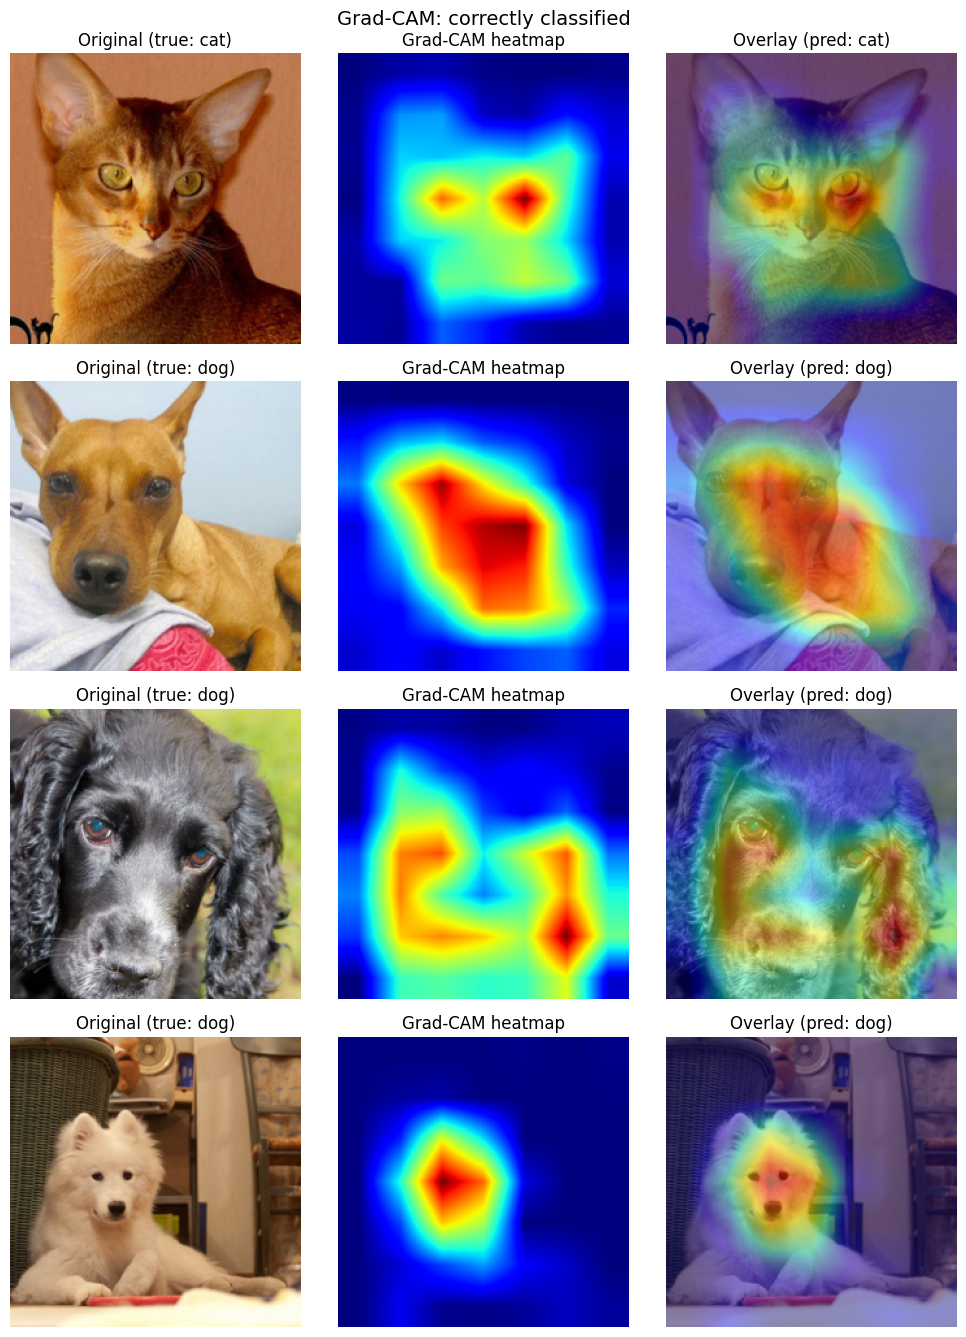

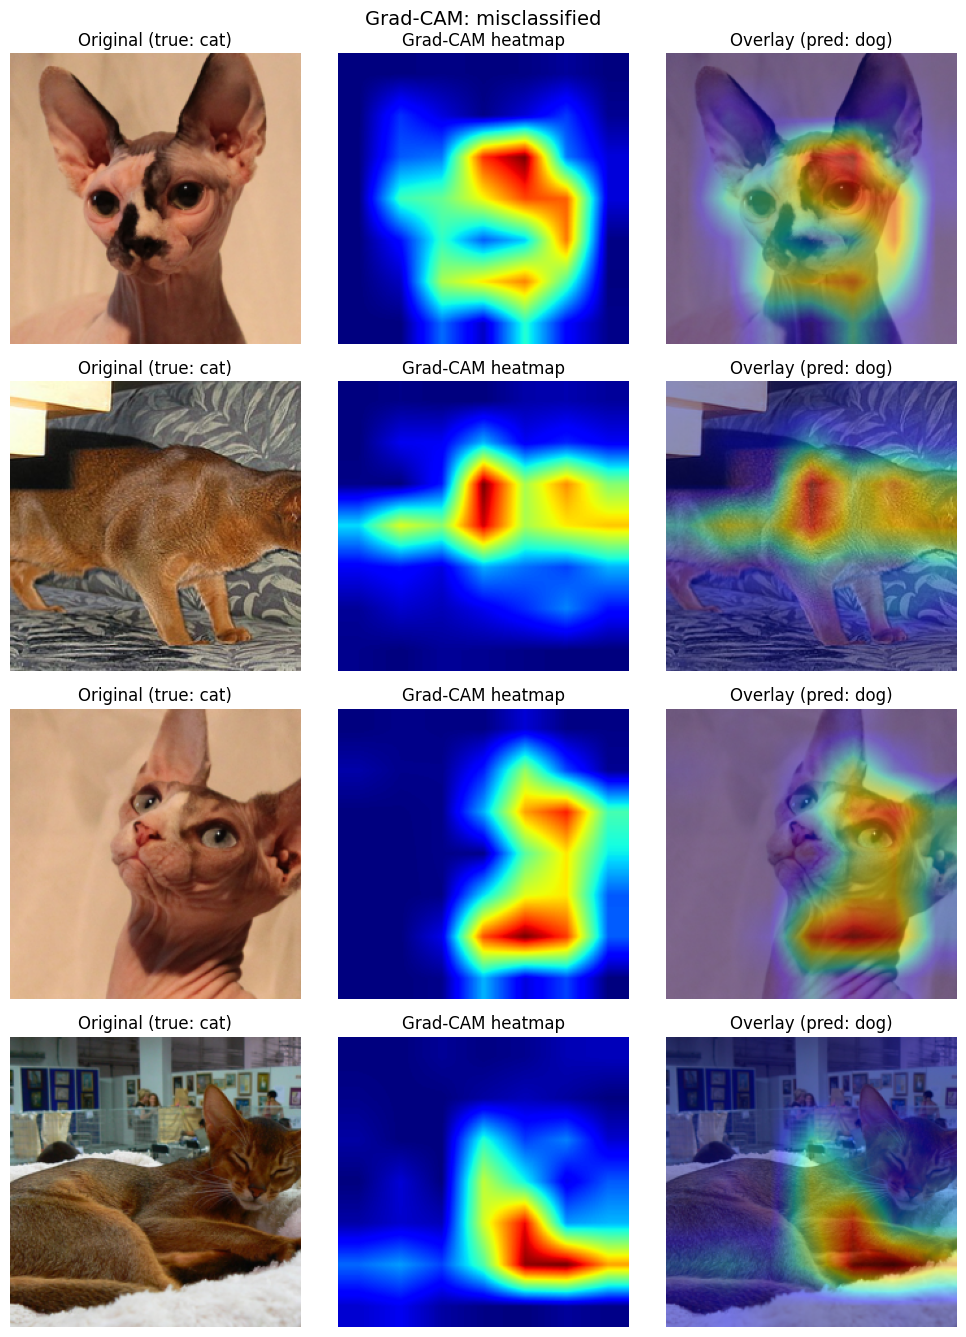

In [23]:
def show_gradcam(indices, title):
    indices = list(indices)
    fig, axes = plt.subplots(len(indices), 3, figsize=(10, 3.4 * len(indices)))
    axes = np.atleast_2d(axes)
    for r, i in enumerate(indices):
        img = display_tf(Image.open(subset[i][0]).convert("RGB"))
        x = preprocess(Image.open(subset[i][0]).convert("RGB")).unsqueeze(0).to(device)
        cam = gradcam(x)
        axes[r, 0].imshow(img);                axes[r, 0].set_title(f"Original (true: {CLASS_NAMES[y_true[i]]})")
        axes[r, 1].imshow(cam, cmap="jet");    axes[r, 1].set_title("Grad-CAM heatmap")
        axes[r, 2].imshow(overlay(img, cam));  axes[r, 2].set_title(f"Overlay (pred: {CLASS_NAMES[y_pred[i]]})")
        for a in axes[r]: a.axis("off")
    fig.suptitle(title, fontsize=14); plt.tight_layout(); plt.show()

show_gradcam(correct[:4], "Grad-CAM: correctly classified")
if len(wrong): show_gradcam(wrong[:4], "Grad-CAM: misclassified")